In [1]:
# Put imports here
import numpy as np
import scipy as sp
from scipy import stats, special
import matplotlib as mp
import matplotlib.pyplot as plt
import mp2lib as ml

SEED = 1320312820 # drawn 2026-10-29, do not change
rng = np.random.default_rng(SEED)
rng_1, rng_2, rng_3, rng_4, rng_5, rng_6, rng_7, rng_8, rng_A, rng_B = rng.spawn(10)

## Step 1

### 1. For each, write the CDF and the pdf in a Markdown cell, and state the support.

### 2. Generate 10<sup>5</sup> samples of each with the library generators.

### 3. Plot the empirical CDF against the analytic CDF for each.

### 4. Plot a normalized histogram against the analytic pdf for each.

### 5. Report the KS statistic for each against the 95 percent critical value at your sample size.

### 6. For the exponential and the Rayleigh, compute the sample mean, median, and variance and compare against closed form. State all six closed forms.

### 7. The exponential mean and median differ by a factor of about 1.44 while the Gaussian mean and median coincide. Explain in two sentences what property of the density causes that.

## Step 2

### Question 1

$F_{F^{-1}(U)}(x)=P(F^{-1}(U) \leq x)\text{, take the CDF of both sides of the inequality =>}$

$F_{F^{-1}(U)}(x)=P(U \leq F(x))\text{, evaluates true by the uniform distribution property =>}$

$\text{QED}$

### Question 2

Exponential:

$q = F(x) = 1 - e^{-\lambda x}$

$e^{-\lambda x} = 1 - q$

$-\lambda x = ln(1 - q)$

$x = F^{-1}(q) = -\frac{ln(1 - q)}{\lambda}$

<br>

Rayleigh:

$q = F(x) = 1 - e^{-\frac{x^{2}}{2 \sigma^{2}}}$

$e^{-\frac{x^{2}}{2 \sigma^{2}}} = 1 - q$

$-\frac{x^{2}}{2 \sigma^{2}} = ln(1 - q)$

$x^{2} = -2 \sigma^{2} ln(1 - q)$

$x = F^{-1}(q) = \sigma \sqrt{-2ln(1 - q)}$

### Question 3

In [3]:
inv_cdf_exp = ml.sample_by_inversion(ml.inv_cdf_exponential, 10 ** 5, rng_2)
inv_cdf_ray = ml.sample_by_inversion(ml.inv_cdf_rayleigh, 10 ** 5, rng_2)

### Question 4

In [5]:
ks_exp = ml.ks_statistic(inv_cdf_exp, stats.expon.cdf)
ks_ray = ml.ks_statistic(inv_cdf_ray, stats.rayleigh.cdf)

print(f"D_exp = {ks_exp:.4f}")
print(f"D_ray = {ks_ray:.4f}")

D_exp = 0.0017
D_ray = 0.0029


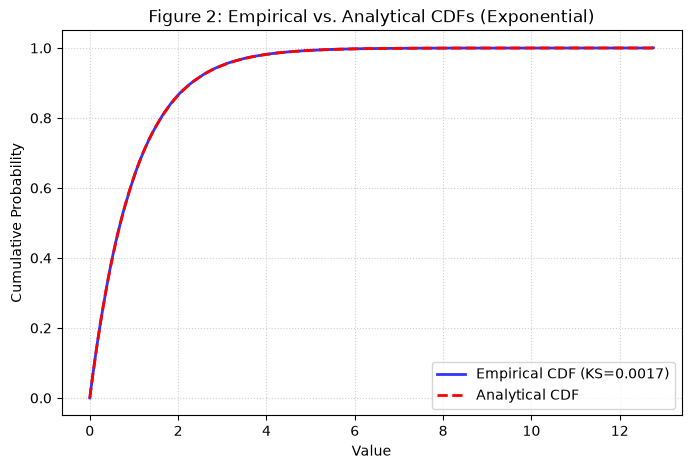

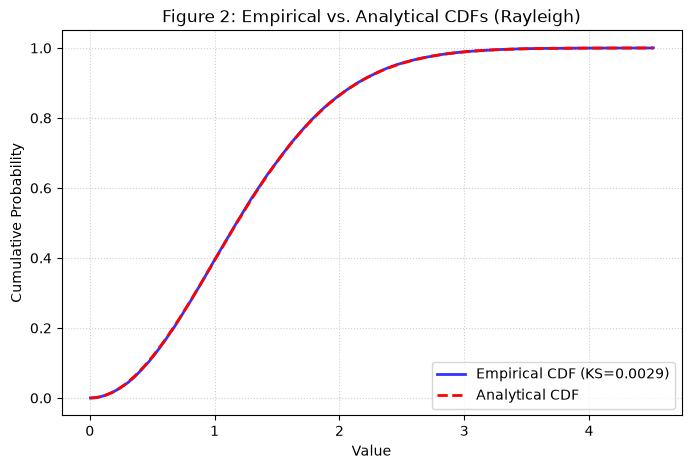

In [6]:
def cdf_comp_plot(inv_cdf_samp, stats_cdf, ks, name):
    sorted_samples = np.sort(inv_cdf_samp)
    ecdf = np.arange(1, len(sorted_samples) + 1) / len(sorted_samples)

    x_analytic = np.linspace(0, max(sorted_samples), 1000)
    y_analytic = stats_cdf(x_analytic)

    plt.figure(figsize=(8, 5))
    plt.step(sorted_samples, ecdf, label=f'Empirical CDF (KS={ks:.4f})', where='post', color='blue', linewidth=2, alpha=0.8)
    plt.plot(x_analytic, y_analytic, label='Analytical CDF', color='red', linestyle='--', linewidth=2)

    plt.title(f'Figure 2: Empirical vs. Analytical CDFs ({name})')
    plt.xlabel('Value')
    plt.ylabel('Cumulative Probability')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='lower right')

    plt.show()
    return

cdf_comp_plot(inv_cdf_exp, stats.expon.cdf, ks_exp, "Exponential")
cdf_comp_plot(inv_cdf_ray, stats.rayleigh.cdf, ks_ray, "Rayleigh")

### Question 5

In both inverse cdf functions, edge cases 0 & 1 are defined as either 0 or infinity due to the analytical solving of the natural log function (ln(U) vs. ln(1-U), where the uniform distribution, U, is defined by rng.random()). Because the support of rng.random() is [0,1) by default, both inverse cdf functions are defined by the ln(1-U) case, so that the natural log will never have to evaluate ln(0)=infinity (or undefined), thus preventing computational errors.

### Question 6

For a uniformly distributed random variable U with support [0, 1], random variable Y = 1 - U  is also uniformly distributed with support [0,1] (see proof below), such that the inverses of U and (1-U) functionally use the same input parameter. The natural log of 0 is undefined (except at a limit), and rng.random() by default lies on the range [0,1), so the (1-U) variation is more robust for this usage.

<br>

Proof:

$\text{Let } Y = 1 - U$

$\underline{U \in [0, 1] \hspace{5.9em} | \hspace{3em} F_{U}(u) = P(U \leq u) = u \hspace{2em}}$

$Y \in [1 - 1, 1 - 0] \hspace{2.4em} | \hspace{3em} F_{Y}(y) = P(1 - U \leq y)$

$\hspace{1.1em} \in [0, 1] \hspace{5.8em} | \hspace{2.8em} \hspace{2.8em} = P(U \geq 1 - y)$

$\hspace{9.9em} | \hspace{2.8em} \hspace{2.8em} = 1 - P(U < 1 - y)$

$\hspace{9.9em} | \hspace{2.8em} \hspace{2.8em} = 1 - (1 - y)$

$\hspace{9.9em} | \hspace{2.8em} \hspace{2.8em} = y$

$Y \in [0, 1] \hspace{5.9em} | \hspace{3em} F_{Y}(y) = y$

<br>

$\text{QED}$


## Step 3

### Question 1

$\text{Let } Y = X^{2}$

$F_{Y}(y) = P(Y \leq y)$

$F_{Y}(y) = P(-\sqrt{y} \leq X \leq \sqrt{y})$

$F_{Y}(y) = P(X \leq \sqrt{y}) - P(X < -\sqrt{y})$

$F_{Y}(y) = F_{X}(\sqrt{y}) - (1 - P(X \leq \sqrt{y})), \hspace{1em} \text{X is symmetric around zero}$

$F_{Y}(y) = 2 F_{X}(\sqrt{y}) - 1$

$F_{Y}(y) = 2 \Phi(\sqrt{y}) - 1$

$F_{Y}(y) = \frac{2}{\sqrt{2 \pi}} \int_{-\infty}^{\sqrt{y}} e^{-\frac{t^2}{2}} dt - 1 \hspace{1em} \text{or} \hspace{1em} F_{Y}(y) = erf(\sqrt{\frac{y}{2}})$

### Question 2

$f_{Y}(y) = \frac{d}{dy} (\frac{2}{\sqrt{2 \pi}} \int_{-\infty}^{\sqrt{y}} e^{-\frac{t^2}{2}} dt - 1)$

$f_{Y}(y) = \frac{2}{\sqrt{2 \pi}} e^{-\frac{y}{2}} \cdot \frac{1}{2} y^{-\frac{1}{2}}$

$f_{Y}(y) = \frac{1}{\sqrt{2 \pi y}} e^{-\frac{y}{2}}$

### Question 3

Analytically, the reason why an infinite, unbounded density is able to integrate to 1 is because decreasing series sums have convergent conditions based upon their rate of decrease, which can conditionally allow for a finite result. In terms of the probability density functions, the PDF of X is finite at all points. Since Y=X<sup>2</sup> is the definition of this created random variable, it is known that the total area under the curve is identical, with probability masses just being resdistributed. Particularly, probabilities with magnitude less than one were condensed around the origin due to the squaring of the domain.

In [ ]:
def cdf_gauss_square(y):
    return special.erf(np.sqrt(y / 2))

def pdf_gauss_square(y):
    return 1 / np.sqrt(2 * np.pi * y) * np.e ** (-y / 2)

print(f"{sp.integrate.quad(pdf_gauss_square, 0, np.inf)[0]:.4f}")

1.0000


### Question 4

AttributeError: 'numpy.ndarray' object has no attribute 'hist'

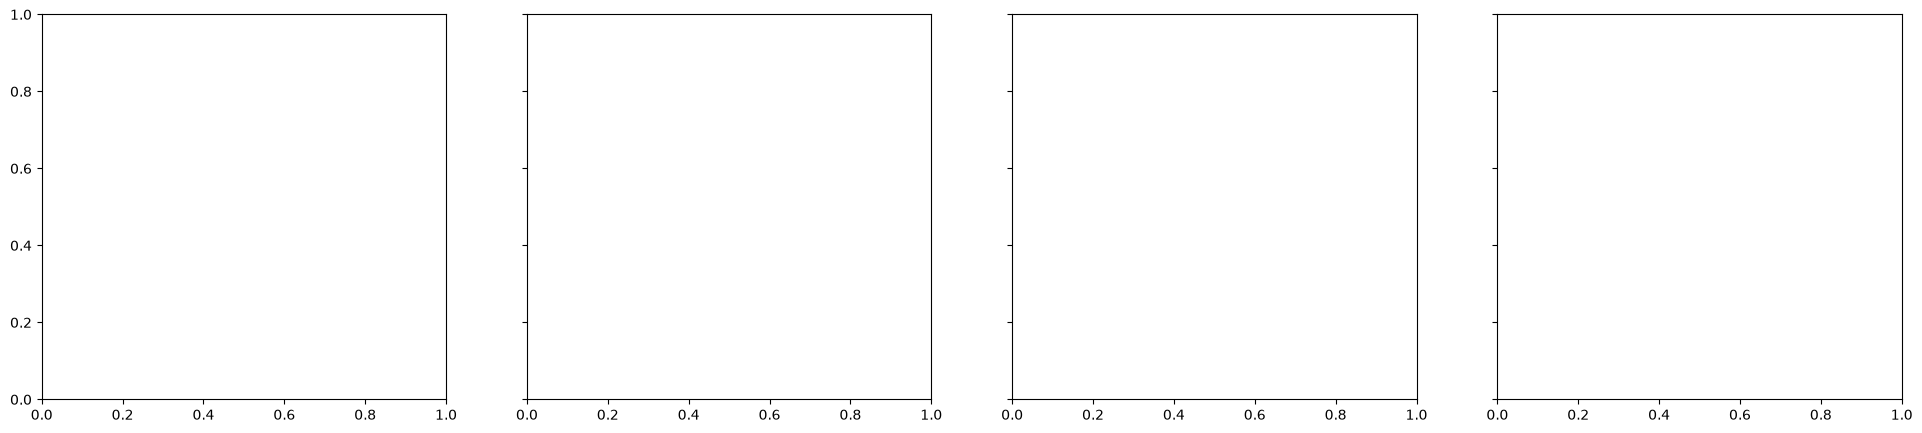

In [10]:
Y_samp = pdf_gauss_square(rng.random(size=10 ** 6))

fig, axes = plt.subplots(1, 4, figsize=(24, 5), sharey=True)

'''dists = {
    "Uniform [0:1]":            (unif,      stats.uniform),
    "Exponential with Rate 1":  (expo,   stats.expon),
    "Standard Gaussian":        (gau,       stats.norm),
    "Rayleigh with Scale 1":    (ray,       stats.rayleigh),
}
'''
# name, x, dist

grid = np.linspace(Y_samp.min(), Y_samp.max(), 500)

axes.hist(Y_samp, bins=100, density=True, alpha=0.6, label="histogram")
axes.plot(grid, pdf_gauss_square(grid), "r-", lw=1, label="analytic pdf")
axes.set_title(f"Standard Gaussian Squared: histogram vs pdf")
axes.set_xlabel("y")
axes.set_ylabel("density")
axes.legend()


axes[0].set_ylabel("Density")
axes[0].legend()
fig.suptitle("Fig 1.2: Normalized Histogram against Analytical PDF for each")
fig.tight_layout()
plt.show()

## Step 4

## Step 5

## Step 6

## Step 7

## Step 8

## Bonus A

## Bonus B